# alpha-PFN: amortized Entropy Search on the BNN prior

## Description

**Question.** Do the registered alpha-PFN checkpoints (Rakotoarison et al., ICML 2026, re-implemented in
pfn-acqpolicy) do what the method claims on our prior: (stage 1) does conditioning on the optimum
x\*, f\* sharpen the PPD, and (stage 2) does the alpha-PFN's mean track the information gain
α̃ = H[q(y|x,D)] − H[q(y|x,D,x\*)] (PES = Entropy Search)? And how does its acquisition relate to
EI, MES, UCB and pure uncertainty (std)?

**Setup.** `alpha_conditioned_large` (stage 1, from `pfn_large`, 156,963 steps) and `alpha_pes_large`
(stage 2, 186,299 steps), both trained on BO-like traces (alpha-PFN's Algorithm 1). Their validation
histories come from the checkpoints. The gates are the rules stated before the original runs: stage 1
at n = 20 for every d: x, f, xf below none, and none within +0.02 nats of step 0; stage 2 at n = 20:
r² > 0 and ρ ≥ 0.1. 1-d panels (n = 4, 10, three draws): the PFN's PPD, the conditioned PPD given the
true x\*, the target α̃ and the alpha-PFN's predictive over α̃, plus EI/MES/UCB/std. Agreement: rank
correlation over 1024 candidates of the alpha-PFN mean with each acquisition, d ∈ {2, 4, 6},
n ∈ {2d, 6d, 12d}, 32 functions.

**What to look for.** Both gates pass (they did originally); in 1-d, α̃ and the alpha-PFN mean are high
where the band is wide *and* reaches below the incumbent, near 0 at evaluated points and where the
optimum is ruled out — unlike std, which is high wherever it is uncertain. The conditioned PPD should
concentrate near f\* around x\*.

**Reproduced / not reproduced.** Reproduced if the gate values match the original checkpoints' histories
(they are read from the files) and the 1-d behaviour matches the original notebook's description
(pfn-acqpolicy notebook 09, B4). The panels and agreement use new draws, so their numbers are new.

**Limits.** In-distribution, d ≤ 6; nothing here measures BO performance (that is pfn-acqpolicy's).

In [ ]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pfn_repro.analysis import load_snapshot, show_header
from pfn_repro.checkpoints import REGISTRY
from pfn_repro.evaluation.plots import ppd_heatmap

SNAPSHOT = "results/eval_alpha_large/sanity_20261021-135935"
snap = load_snapshot(SNAPSHOT)
show_header(snap)
plt.rcParams.update({"figure.dpi": 85, "axes.spines.top": False, "axes.spines.right": False})
CASE = {"none": "#7f7f7f", "x": "#0072B2", "f": "#D55E00", "xf": "#009E73"}

## How it was run

```bash
just sweep detached sanity experiment=eval_alpha_large
```

|  |  |
|---|---|
| stage | sanity |
| sweep | `sanity_20261021-135935` |
| commit | `52bf85a8836f` (tag `sweep/eval_alpha_large/sanity_20261021-135935`) |
| backend / host | detached / ulysses |
| ran | 2026-10-21T13:59:37 → 2026-10-21T14:00:46 |
| members | 1: 1 done |
| compute | 1.1 min wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/eval_alpha_large.yaml`):

```yaml
# @package _global_
# The registered alpha-PFN pair: histories, gates, 1-d panels, agreement.
defaults:
  - /prior: bnn
  - override /task: eval_alpha
```

**Varying:** nothing

**Replicates:** none

**Constant:**

```yaml
prior:
  bias_std: 0.1
  depth_range: '[8, 32]'
  frac_relevant_features: 0.7
  log_amp_range: '[8.0, 20.0]'
  name: bnn
  output_noise_std_range: '[0.0004, 0.0013]'
  preactivation_noise_std_range: '[0.0003, 0.0014]'
  sparseness: 0.145
  width_range: '[32, 128]'
seed: 0
task:
  agreement.context_multiples: '[2, 6, 12]'
  agreement.dims: '[2, 4, 6]'
  agreement.n_candidates: 1024
  agreement.n_functions: 32
  agreement.seed: 9100
  alpha: alpha_pes_large
  base: pfn_large
  conditioned: alpha_conditioned_large
  gate_dims: '[1, 2, 4, 6]'
  name: eval_alpha
  panels.contexts: '[4, 10]'
  panels.density_x: 120
  panels.max_bins: 200
  panels.n_functions: 3
  panels.n_grid: 400
  panels.seed: 9001
  threads: 8
  val_every: 5000
```

## 1. The checkpoints

Read from the registry (`checkpoints.py`), which pins each file by sha256. The training provenance is
the original run in pfn-acqpolicy.

In [ ]:
pd.DataFrame([{"name": n, "kind": REGISTRY[n].kind, "sha256": REGISTRY[n].sha256[:12] + "…",
               "description": REGISTRY[n].description, **{k: REGISTRY[n].source.get(k) for k in ("git_commit", "step", "base")}}
              for n in ("pfn_large", "alpha_conditioned_large", "alpha_pes_large")]).style.hide(axis="index")

name,kind,sha256,description,git_commit,step,base
pfn_large,pfn,00c656d9ed82…,"long-run PFN: 6.6M params (d_model 256, 8 layers, 1000 bins), 1.5M steps x 64 functions",0b5683e8220e4947152544e45cf3cdc508ae3732,1499999,nan
alpha_conditioned_large,conditioned,f677cc8e6016…,"alpha-PFN stage 1: q(y | x, D, I), I in {none, x*, f*, both}; fine-tuned from pfn_large",4d92fd5d343e4166c2d2286eda73c39d0586536f,156962,pfn_large
alpha_pes_large,alpha,1428e4ed7dff…,alpha-PFN stage 2 (PES = Entropy Search): bar distribution over alpha~; its mean is the acquisition value (maximize),4d92fd5d343e4166c2d2286eda73c39d0586536f,186298,pfn_large


## 2. Training curves

**What to look for:** a falling, flattening training NLL, and a learning rate that reaches 0 at the
last step (the cosine schedule was fitted to a deadline).

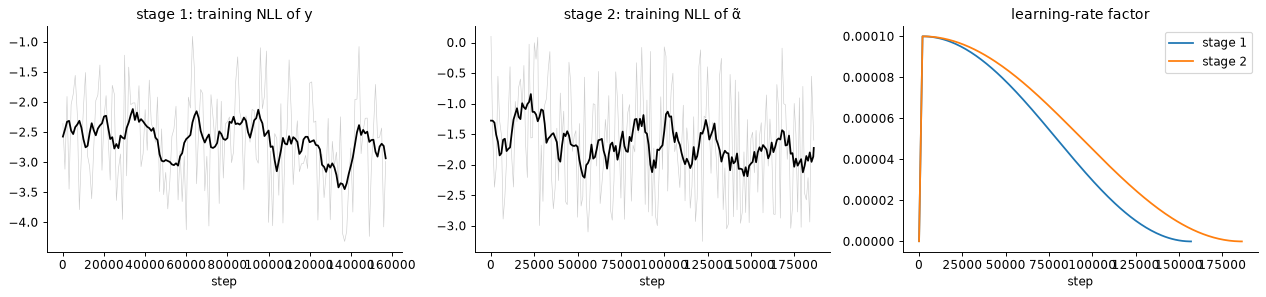

In [ ]:
hc, ha = snap.table("history_conditioned"), snap.table("history_alpha")
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, h, title in ((ax[0], hc, "stage 1: training NLL of y"), (ax[1], ha, "stage 2: training NLL of α̃")):
    a.plot(h.step, h["nll/train"], color="#cccccc", lw=0.5)
    a.plot(h.step, h["nll/train"].rolling(9, center=True, min_periods=1).mean(), "k", lw=1.5)
    a.set_title(title); a.set_xlabel("step")
ax[2].plot(hc.step, hc.lr, label="stage 1"); ax[2].plot(ha.step, ha.lr, label="stage 2")
ax[2].set_title("learning-rate factor"); ax[2].legend(); ax[2].set_xlabel("step"); fig.tight_layout(); plt.show()

## 3. Stage 1: does knowing the optimum help predict y?

Held-out NLL at n = 20 per d, conditioned on nothing, on x\*, on f\*, or on both. **What to look for:**
x, f and xf below none; none flat (it is the base PFN at step 0).

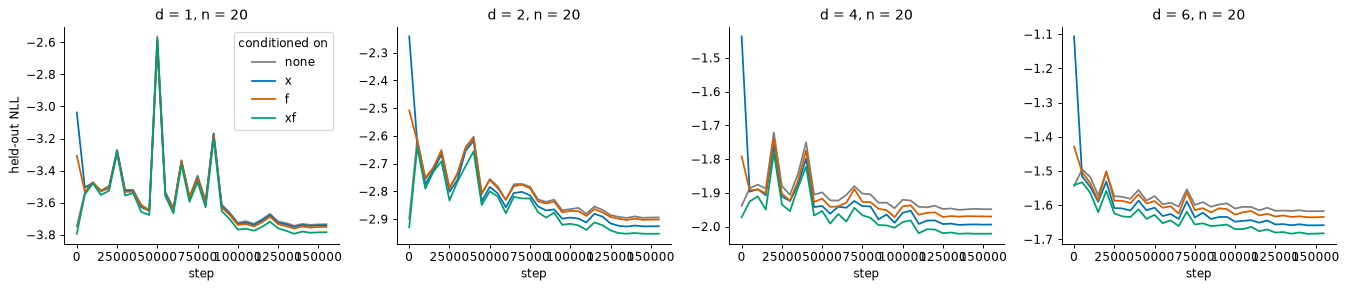

NLL gain from conditioning on x* and f* (nats, final validation):


,n = 5,n = 20,n = 50
d,,,
1,0.286,0.050,0.014
2,0.265,0.059,0.024
4,0.218,0.073,0.024
6,0.115,0.065,0.032


In [ ]:
dims = [1, 2, 4, 6]
v = hc.dropna(subset=["nll/val_d1_n20_none"])
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for a, d in zip(axes, dims):
    for case, col in CASE.items():
        a.plot(v.step, v[f"nll/val_d{d}_n20_{case}"], color=col, label=case)
    a.set_title(f"d = {d}, n = 20"); a.set_xlabel("step")
axes[0].set_ylabel("held-out NLL"); axes[0].legend(title="conditioned on"); fig.tight_layout(); plt.show()
gain = pd.DataFrame({f"n = {n}": {d: v.iloc[-1][f"nll/val_d{d}_n{n}_none"] - v.iloc[-1][f"nll/val_d{d}_n{n}_xf"] for d in dims}
                     for n in (5, 20, 50)})
gain.index.name = "d"; print("NLL gain from conditioning on x* and f* (nats, final validation):"); gain.round(3)

## 4. Stage 2: does the alpha-PFN predict the information gain?

r² of the predicted mean against the single-draw target α̃, and ρ, the rank correlation across the query
points of one context (what maximizing an acquisition uses). α̃ is one noisy draw per point, so the
best achievable values are well below 1.

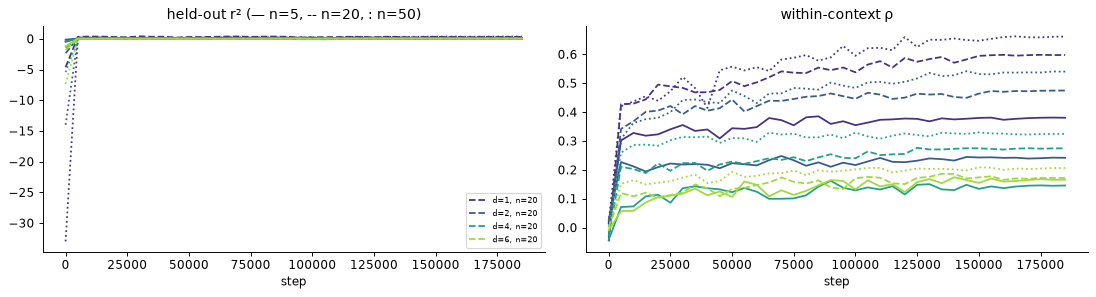

In [ ]:
va = ha.dropna(subset=["r2/val_d1_n20"])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for d in dims:
    for n, ls in zip((5, 20, 50), ("-", "--", ":")):
        ax[0].plot(va.step, va[f"r2/val_d{d}_n{n}"], ls, color=plt.cm.viridis(d / 7), label=f"d={d}, n={n}" if n == 20 else None)
        ax[1].plot(va.step, va[f"rho/val_d{d}_n{n}"], ls, color=plt.cm.viridis(d / 7))
ax[0].set_title("held-out r² (— n=5, -- n=20, : n=50)"); ax[1].set_title("within-context ρ"); ax[0].legend(fontsize=7)
for a in ax: a.set_xlabel("step")
fig.tight_layout(); plt.show()

## 5. The gates

The rules stated before the original runs, evaluated on the checkpoints' own validation histories.

In [ ]:
g = snap.table("gates").drop(columns="member")
print("all gates passed:", bool(g.passed.all()))
g.round(4).style.hide(axis="index")

all gates passed: True


stage,d,criterion,value,threshold,passed
conditioned,1,x below none,-0.007100,0.000000,True
conditioned,1,f below none,-0.016800,0.000000,True
conditioned,1,xf below none,-0.049600,0.000000,True
conditioned,1,none drift from step 0,0.013200,0.020000,True
conditioned,2,x below none,-0.031900,0.000000,True
conditioned,2,f below none,-0.007600,0.000000,True
conditioned,2,xf below none,-0.058600,0.000000,True
conditioned,2,none drift from step 0,0.004300,0.020000,True
conditioned,4,x below none,-0.045500,0.000000,True
conditioned,4,f below none,-0.021800,0.000000,True


## 6. 1-d behaviour: PPDs, the target α̃ and the acquisition

Three 1-d draws, contexts of n = 4 and n = 10 (uniform random points, noise-free y). Per function, top to
bottom:
1. the base PFN's PPD on its bar intervals, with its mean, the 5–95% band, the true f, the context and
   x\* (star);
2. the conditioned PPD given the true x\*;
3. the alpha-PFN's predictive over α̃ on its own (quantile) intervals, its mean, and the target α̃
   computed from the true x\*;
4. all acquisitions min–max scaled (dotted lines: their argmax).

**What to look for:** α̃ and the alpha-PFN mean should be high where the band is wide *and* reaches below
the incumbent, and near 0 at evaluated points and where the optimum is ruled out. std is high wherever
the PFN is uncertain. Failure modes to spot: an acquisition peaking where the minimum is ruled out, a
conditioned PPD that ignores x\*, an α̃ predictive that is flat in x.

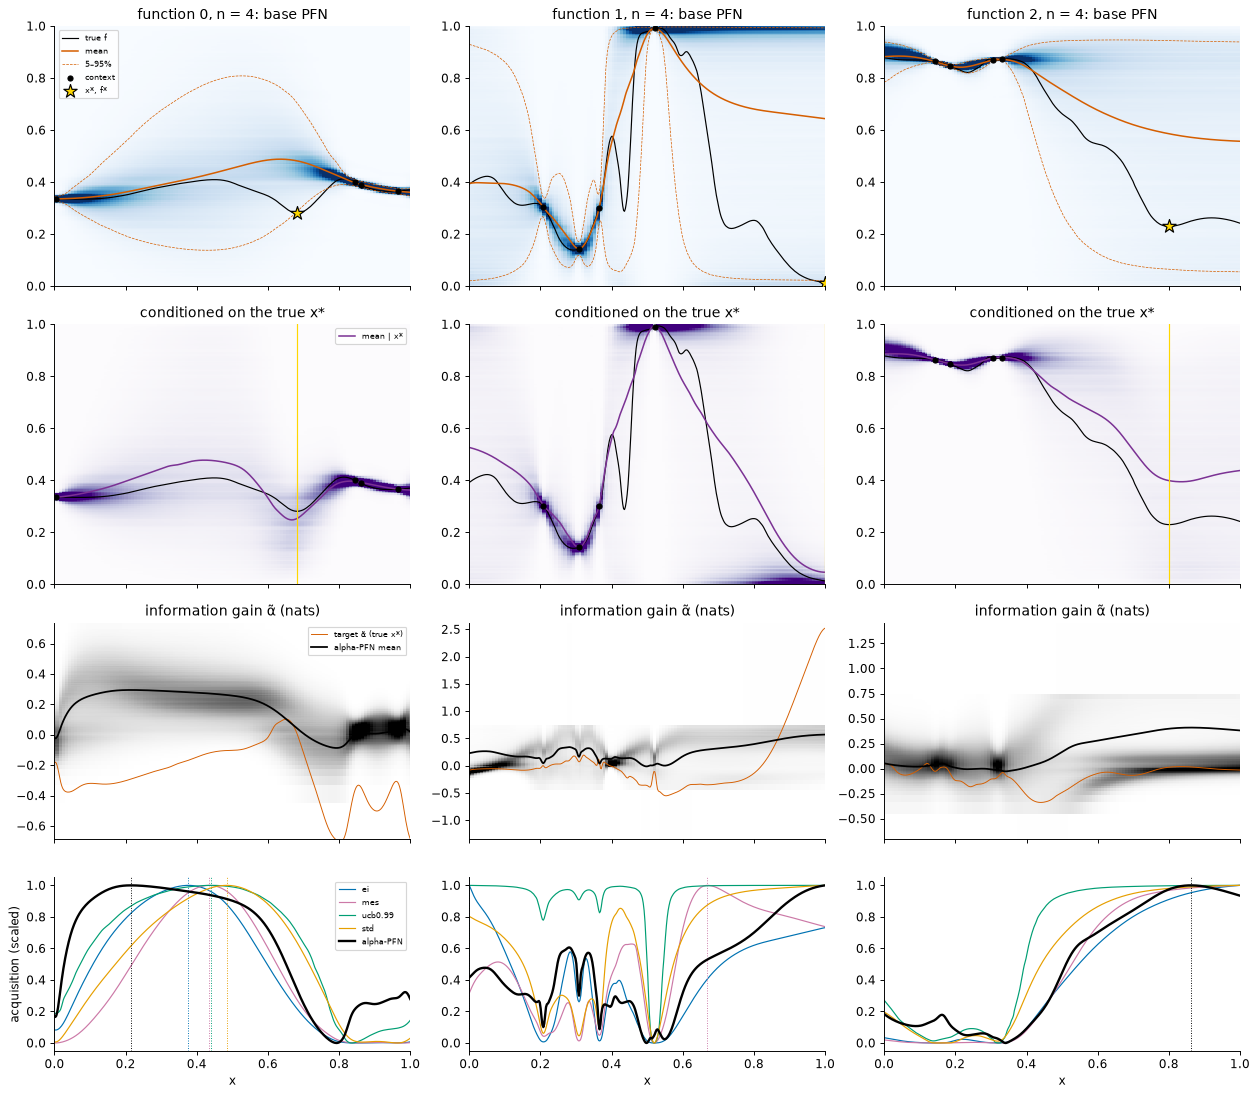

In [ ]:
L, C, D, B, O = (snap.table(t) for t in ("panel_lines", "panel_context", "panel_density", "panel_borders", "panel_optimum"))
ACQ = {"ei": "#0072B2", "mes": "#CC79A7", "ucb0.99": "#009E73", "std": "#E69F00", "alpha_mean": "k"}

def panel(n):
    fig, axes = plt.subplots(4, 3, figsize=(15, 13), sharex=True, gridspec_kw={"height_ratios": [1.2, 1.2, 1, 0.8]})
    for b in range(3):
        l, c, o = L[(L.function == b) & (L.n == n)], C[(C.function == b) & (C.n == n)], O[O.function == b].iloc[0]
        for row, kind, cmap in ((0, "pfn", "Blues"), (1, "conditioned", "Purples"), (2, "alpha", "Greys")):
            ax = axes[row, b]
            ppd_heatmap(ax, D[(D.kind == kind) & (D.function == b) & (D.n == n)], B[B.kind == kind], cmap=cmap)
        ax = axes[0, b]
        ax.plot(l.x, l.f_true, "k", lw=1, label="true f"); ax.plot(l.x, l.pfn_mean, color="#D55E00", lw=1.3, label="mean")
        ax.plot(l.x, l.pfn_q05, color="#D55E00", lw=0.6, ls="--"); ax.plot(l.x, l.pfn_q95, color="#D55E00", lw=0.6, ls="--", label="5–95%")
        ax.scatter(c.x, c.y, color="k", zorder=5, s=18, label="context"); ax.scatter([o.x_opt], [o.f_opt], marker="*", s=140, color="gold", edgecolor="k", zorder=6, label="x*, f*")
        ax.set_ylim(0, 1); ax.set_title(f"function {b}, n = {n}: base PFN")
        ax = axes[1, b]
        ax.plot(l.x, l.f_true, "k", lw=1); ax.plot(l.x, l.cond_mean, color="#7B3294", lw=1.3, label="mean | x*")
        ax.scatter(c.x, c.y, color="k", zorder=5, s=18); ax.axvline(o.x_opt, color="gold", lw=1); ax.set_ylim(0, 1)
        ax.set_title("conditioned on the true x*")
        ax = axes[2, b]
        ax.plot(l.x, l.alpha_target, color="#D55E00", lw=0.8, label="target α̃ (true x*)")
        ax.plot(l.x, l.alpha_mean, "k", lw=1.5, label="alpha-PFN mean"); ax.set_title("information gain α̃ (nats)")
        lo, hi = np.quantile(np.r_[l.alpha_q05, l.alpha_target], 0.01), np.quantile(np.r_[l.alpha_q95, l.alpha_target], 0.99)
        ax.set_ylim(min(lo, -0.05), hi * 1.1 + 0.05)
        ax = axes[3, b]
        for k, col in ACQ.items():
            s = l[k].to_numpy(); s = (s - s.min()) / (s.max() - s.min() + 1e-12)
            ax.plot(l.x, s, color=col, lw=2 if k == "alpha_mean" else 1, label="alpha-PFN" if k == "alpha_mean" else k)
            ax.axvline(l.x.iloc[int(s.argmax())], color=col, ls=":", lw=0.8)
        ax.set_xlabel("x")
    axes[0, 0].legend(fontsize=7, loc="upper left"); axes[1, 0].legend(fontsize=7); axes[2, 0].legend(fontsize=7); axes[3, 0].legend(fontsize=7)
    axes[3, 0].set_ylabel("acquisition (scaled)"); fig.tight_layout(); plt.show()

panel(4)

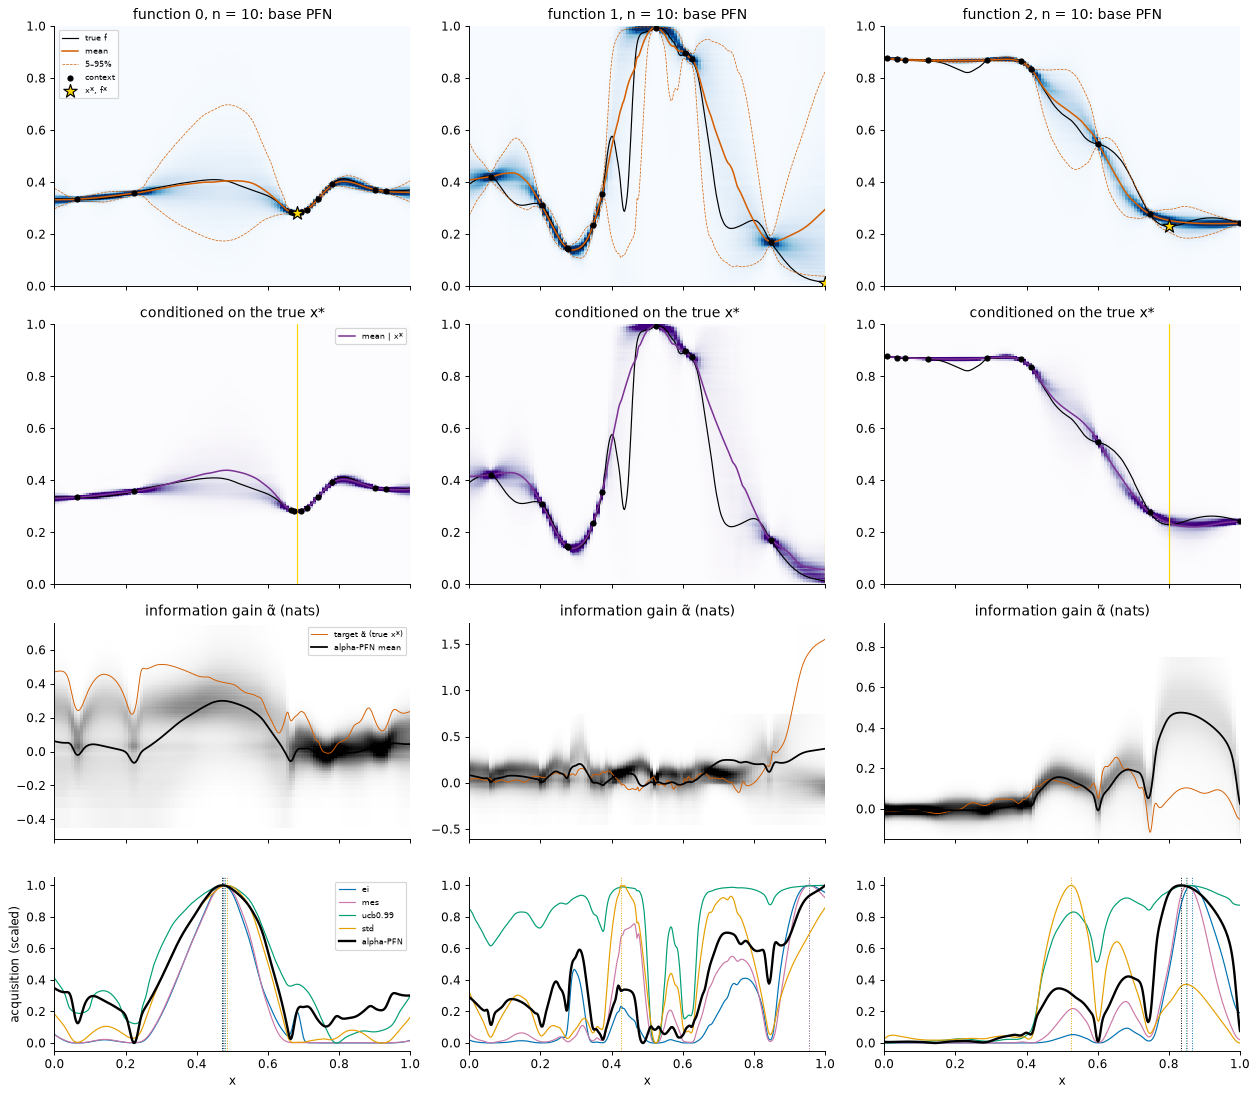

In [ ]:
panel(10)

## 7. Agreement with standard acquisitions on fresh contexts

Spearman correlation over 1024 candidates between the alpha-PFN mean and each acquisition (mean = −posterior
mean, i.e. exploitation), averaged over 32 functions; and how far apart their argmaxes are, relative to the
mean distance of two uniform points.

In [ ]:
ag = snap.table("agreement")
display(ag.pivot_table(index="vs", columns=["d", "n"], values="spearman").round(2))
ag.pivot_table(index="vs", columns=["d", "n"], values="argmax_distance").round(2)

d           2                 4                 6            
n          4     12    24    8     24    48    12    36    72
vs                                                           
ei       0.50  0.70  0.48  0.50  0.67  0.56  0.43  0.64  0.55
mean     0.32  0.49  0.34  0.38  0.58  0.55  0.38  0.64  0.60
mes      0.49  0.63  0.45  0.45  0.63  0.47  0.35  0.63  0.51
std      0.33  0.39  0.29  0.28  0.16  0.23 -0.10 -0.07  0.03
ucb0.99  0.48  0.67  0.45  0.50  0.67  0.63  0.44  0.67  0.67

d           2                 4                 6            
n          4     12    24    8     24    48    12    36    72
vs                                                           
ei       0.95  0.50  0.72  0.91  0.59  0.64  0.78  0.49  0.54
mean     0.93  0.62  0.66  0.87  0.68  0.67  0.77  0.52  0.67
mes      0.82  0.65  0.62  0.90  0.67  0.64  0.81  0.53  0.58
std      1.20  1.00  1.06  1.17  1.11  0.98  1.26  1.09  0.92
ucb0.99  1.05  0.68  0.57  0.95  0.57  0.57  0.91  0.48  0.49

## Verdict

**Reproduced.** All 24 gate criteria pass, with the values the original analysis reported. The gate
values are read from the checkpoints themselves, so this confirms that the registered files are the
evaluated ones and that the port reads them correctly.
- **Stage 2 at n = 20:** ρ = 0.60 / 0.47 / 0.27 / 0.17 and r² = 0.32 / 0.15 / 0.06 / 0.04 for
  d = 1, 2, 4, 6.
- **Stage 1:** conditioning on x\* and f\* gains 0.12–0.29 nats at n = 5, 0.05–0.07 at n = 20 and
  0.01–0.03 at n = 50.
- **Agreement** (same seeds as the original): Spearman 0.43–0.70 with EI and UCB0.99, 0.35–0.63 with
  MES, and −0.10 to 0.39 with std. As before, it has the least to do with pure uncertainty sampling.

**What we see.**
- **Training.** Both stages end at learning rate 0 (the deadline-fitted cosine annealed). Training NLL
  fell from −2.48 to −2.91 (stage 1) and from −1.62 to −1.94 (stage 2).
- **Stage 1 curves.** x, f and xf lie below none at every d from about 50k steps on; xf is best.
  d = 1 is noisy (a joint spike at 50k in all four cases), but the order holds. none did not drift
  up: at d = 6 it ended 0.07 nats *better* than step 0, so fine-tuning on traces also improved the
  base PFN.
- **Stage 2 signal.** It weakens with d (ρ 0.60 → 0.17 at n = 20) and grows with n (d = 6: ρ = 0.21 at n = 50).
- **1-d behaviour, as Entropy Search should.**
  - The alpha-PFN mean is near 0 at evaluated points and high where the band is wide and reaches
    low values.
  - Unlike std, it ignores uncertain regions that can't hold the minimum. Function 2 at n = 10: std
    peaks at x ≈ 0.52 (uncertain, but high-valued); the alpha-PFN peaks at 0.82, beside the true
    x\* = 0.80, as do EI and MES.
  - Function 1: the minimum sits on the boundary (x\* = 1, f\* = 0.01), and the alpha-PFN ranks the
    right edge highest at both n.
- **The target α̃ is one noisy draw.** Its expectation is the information gain, but a single draw can
  be negative over wide ranges (function 0, n = 4: about −0.3 left of x\*). The alpha-PFN learns the
  expectation, so its mean and the single-draw target disagree pointwise. That is why r² stays small
  even when ρ is substantial.
- **The conditioned PPD uses x\*.** Given the true x\*, the density and mean dip towards f\* at x\*
  (function 0, n = 4: the mean drops to about 0.25 at x\* = 0.68, where the base PFN's mean is 0.48).
  The dip can be partial: function 2, n = 4: about 0.40 against f\* = 0.23.
- **Failure modes to remember** (the base PFN at n = 4):
  - A narrow dip between context points is invisible (function 1, x ≈ 0.43).
  - Far from data the mean regresses to about 0.55–0.65 while the true function falls to about 0.2
    (functions 1 and 2, right half). The 5–95% band still covers it, so the uncertainty is honest,
    but mean-based choices would miss it.

No decision is recorded: this is a sanity check of the port, which passed.